In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 01 — Data exploration
What the data look like before any modelling: coverage, class balance, home advantage, goals, odds availability, and OL's history. Source and terms: `docs/data_sources.md`.

In [2]:
m = pd.read_parquet(PROC / "matches.parquet")
print(f"{len(m):,} matches, {m.date.min():%Y-%m-%d} -> {m.date.max():%Y-%m-%d}, {m.home.nunique()} home teams")
pd.crosstab(m.season, m.league)

29,239 matches, 2010-08-07 -> 2026-10-21, 189 home teams


league,D1,E0,F1,I1,SP1
season,,,,,
2010,306,380,380,380,380
2011,306,380,380,380,380
2012,306,380,380,380,380
2013,306,380,380,380,380
2014,306,380,380,380,380
2015,306,380,380,380,380
2016,306,380,380,380,380
2017,306,380,380,380,380
2018,306,380,380,380,380


**2019/20** is truncated by COVID (Ligue 1 stopped early); Ligue 1 and the Bundesliga have 18 teams (306 matches), the others 20 (380).

result,H,D,A
league,,,
D1,0.448,0.244,0.308
E0,0.447,0.243,0.310
F1,0.442,0.265,0.293
I1,0.433,0.259,0.308
SP1,0.466,0.251,0.283


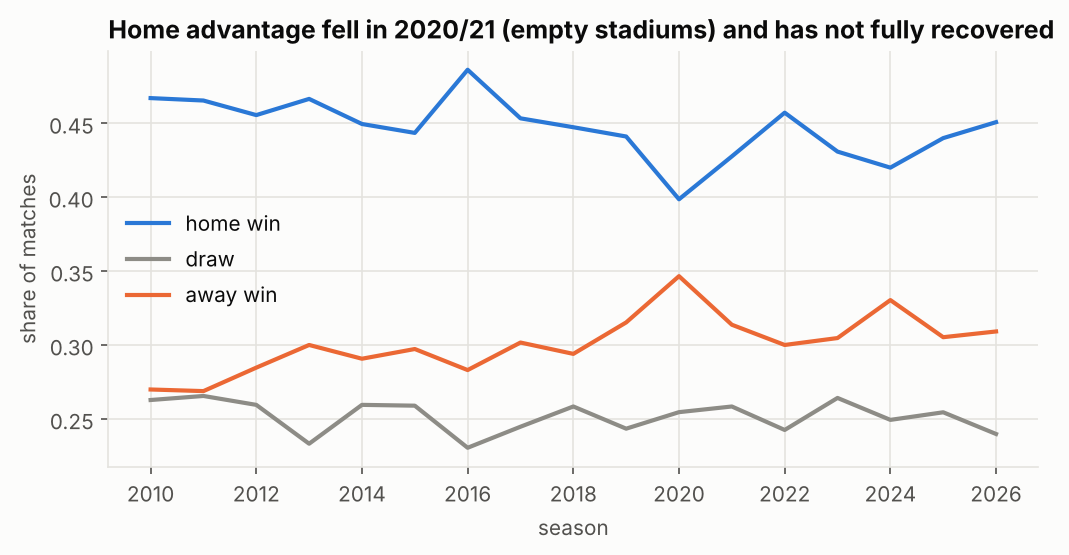

In [3]:
res = pd.crosstab(m.league, m.result, normalize="index")[["H", "D", "A"]]
display(res.round(3))
by_season = m.groupby("season").apply(lambda g: pd.Series({"home win": (g.result=="H").mean(),
                                                        "draw": (g.result=="D").mean(), "away win": (g.result=="A").mean()}),
                                      include_groups=False)
ax = by_season.plot(figsize=(8, 3.6), color=[style.BLUE, style.NEUTRAL, style.ORANGE], lw=2)
ax.set_ylabel("share of matches"); ax.set_title("Home advantage fell in 2020/21 (empty stadiums) and has not fully recovered")
plt.show()

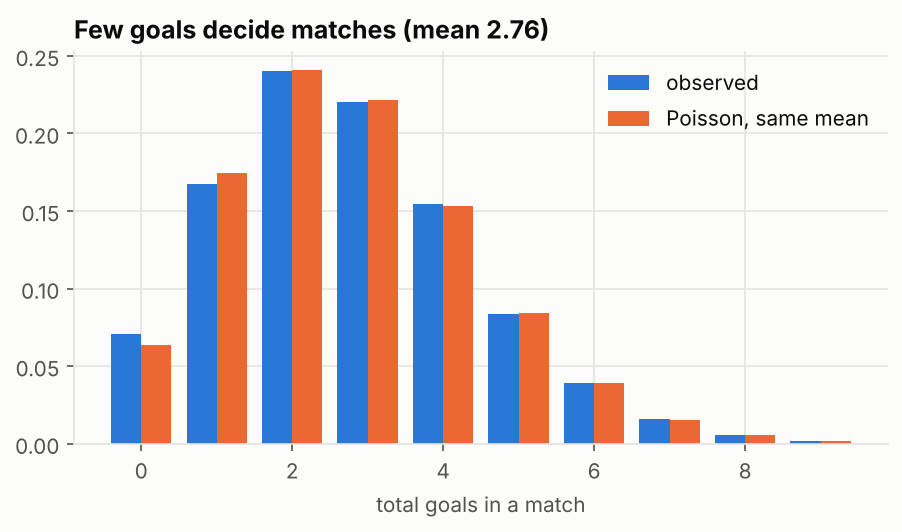

In [4]:
goals = (m.home_goals + m.away_goals)
fig, ax = plt.subplots(figsize=(7, 3.4))
obs = goals.value_counts(normalize=True).sort_index().iloc[:10]
from scipy.stats import poisson
ax.bar(obs.index - 0.2, obs.values, width=0.4, color=style.BLUE, label="observed")
ax.bar(obs.index + 0.2, poisson.pmf(obs.index, goals.mean()), width=0.4, color=style.ORANGE, label="Poisson, same mean")
ax.set_xlabel("total goals in a match"); ax.legend(); ax.set_title(f"Few goals decide matches (mean {goals.mean():.2f})")
plt.show()

In [5]:
cov = m.groupby("season")[["b365_h", "avg_h", "hs", "hst"]].agg(lambda s: s.notna().mean())
cov.columns = ["Bet365 odds", "market-average odds", "shots", "shots on target"]
cov.round(2)

,Bet365 odds,market-average odds,shots,shots on target
season,,,,
2010,1.0,0.0,1.0,1.0
2011,1.0,0.0,1.0,1.0
2012,1.0,0.0,1.0,1.0
2013,1.0,0.0,1.0,1.0
2014,1.0,0.0,1.0,1.0
2015,1.0,0.0,1.0,1.0
2016,1.0,0.0,1.0,1.0
2017,1.0,0.0,1.0,1.0
2018,1.0,0.0,1.0,1.0


Bet365 odds exist for essentially every match; the market average only from 2019/20. Shots are available throughout.

In [6]:
from olpred.predict.league import table_from
rows = []
for (lg, s), g in m[m.league == "F1"].groupby(["league", "season"]):
    t = table_from(g); t["key"] = t.pts*1e6 + (t.gd+1000)*1e3 + t.gf
    t["pos"] = t.key.rank(ascending=False, method="first").astype(int)
    if "Lyon" in t.index and len(g) >= 300:
        rows.append((s, int(t.loc["Lyon", "pts"]), int(t.loc["Lyon", "pos"])))
ol = pd.DataFrame(rows, columns=["season", "points", "position"]).set_index("season")
display(ol.T)

season,2010,2011,2012,2013,2014,2015,2016,2017,2018,2020,2021,2022,2023,2024,2025
points,64,64,67,61,75,65,67,78,72,76,62,62,53,57,60
position,3,4,3,5,2,2,4,3,3,4,7,7,6,6,4


*(Complete seasons only. The `season` label is the year in which the season starts.)*